## Figure 4 — DAX kernel hardware results

This results-only notebook loads the DAX graph and hardware counts, computes the ground-truth MIS and the fixed independent-set measurements, then plots the independent-set-size distribution alongside top-two-size normalized node marginals. Green marks nodes in at least one ground-truth MIS; red outlines mark the six highest-marginal candidates. No Helios jobs are submitted.

In [1]:
%matplotlib inline
import os
import sys
import json

# Find the project root from the notebook's working directory.
def _find_repo_root(start=None):
    directory = os.path.abspath(start or os.getcwd())
    while True:
        if (os.path.isfile(os.path.join(directory, 'pyproject.toml'))
                and os.path.isdir(os.path.join(directory, 'qReduMIS_package'))):
            return directory
        parent = os.path.dirname(directory)
        if parent == directory:
            raise RuntimeError('Run this notebook from within the qReduMIS repository')
        directory = parent

ROOT = _find_repo_root()
BASE = os.path.join(ROOT, 'results_experiments', 'quantum_informed_portfolio_selection')
sys.path.insert(0, BASE)  # results-only utils/
sys.path.insert(0, os.path.join(ROOT, 'qReduMIS_package'))

# networkx 2.8.8 uses legacy NumPy aliases removed in NumPy 2.
import numpy as np
for legacy, modern in (('float_', 'float64'), ('int_', 'int64'),
                       ('complex_', 'complex128'), ('unicode_', 'str_')):
    if not hasattr(np, legacy):
        setattr(np, legacy, getattr(np, modern))

import networkx as nx
from qReduMIS.solver.classical_reducer.reducer import Reducer

os.chdir(BASE)  # resolve stored results paths from the release root
SAVE_FIGURES = False  # set False to skip saving figures


In [2]:
path = "problem_instances/hardware/graph_unweighted_dax_N85_seed0_thres0.24.graphml"
initial_graph = nx.read_graphml(path)

In [3]:
# Exact MIS size of the reduced DAX kernel (needed for the vertical reference).
from utils.solver_baseline import or_tool_solver as maximum_independent_set

In [4]:
from copy import deepcopy

graph_simple, removed, selected = Reducer(verbose=False).reduce(deepcopy(initial_graph))

In [5]:
gt_nodes_kernel = maximum_independent_set(graph_simple)
gt_size_kernel = len(gt_nodes_kernel)

In [6]:
# Load the 100 recorded DAX hardware shots (no hardware jobs are submitted).
counts_path = "individual_results/hardware_counts/dax/dax_measurement_counts_raw.json"
with open(counts_path) as f:
    raw_counts = json.load(f)

In [7]:
def enumerate_independent_sets(G, target_size):
    """Return all independent sets of exactly target_size in G."""
    nodes = sorted(G.nodes(), key=lambda v: G.degree(v), reverse=True)
    adj = {v: set(G.neighbors(v)) for v in nodes}
    results = []

    def _backtrack(candidates, current):
        if len(current) == target_size:
            results.append(frozenset(current))
            return
        remaining_needed = target_size - len(current)
        for i, v in enumerate(candidates):
            if len(candidates) - i < remaining_needed:
                return
            new_candidates = [u for u in candidates[i + 1:] if u not in adj[v]]
            _backtrack(new_candidates, current + [v])

    _backtrack(nodes, [])
    return results

all_mis = enumerate_independent_sets(graph_simple, gt_size_kernel)

In [8]:
# Mark nodes belonging to at least one exact MIS of the kernel.
gt_frozen_nodes = set().union(*all_mis)
all_nodes = sorted(graph_simple.nodes())

In [9]:
from collections import Counter
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
from qReduMIS.solver.informers.corrector_strategies.fixer import (
    get_fixup_sol, remove_with_check_and_add,
)

# Apply the paper's fixup, then restrict node marginals to the two largest IS sizes.
fixup_counts = get_fixup_sol(
    deepcopy(raw_counts), list(graph_simple.edges()), remove_with_check_and_add
)
size_set = {len(e['nodes']) for e in fixup_counts}
top2_sizes = sorted(size_set, reverse=True)[:2]
top2_counts = [e for e in fixup_counts if len(e['nodes']) in top2_sizes]
total_top2 = sum(e['count'] for e in top2_counts)
node_counts_top2 = Counter()
for e in top2_counts:
    for n in e['nodes']:
        node_counts_top2[n] += e['count']
marginals_top2 = {n: node_counts_top2.get(n, 0) / total_top2 for n in all_nodes}
marginal_sum_top2 = sum(marginals_top2.values())
norm_probs_top2 = [marginals_top2[n] / marginal_sum_top2 for n in all_nodes]


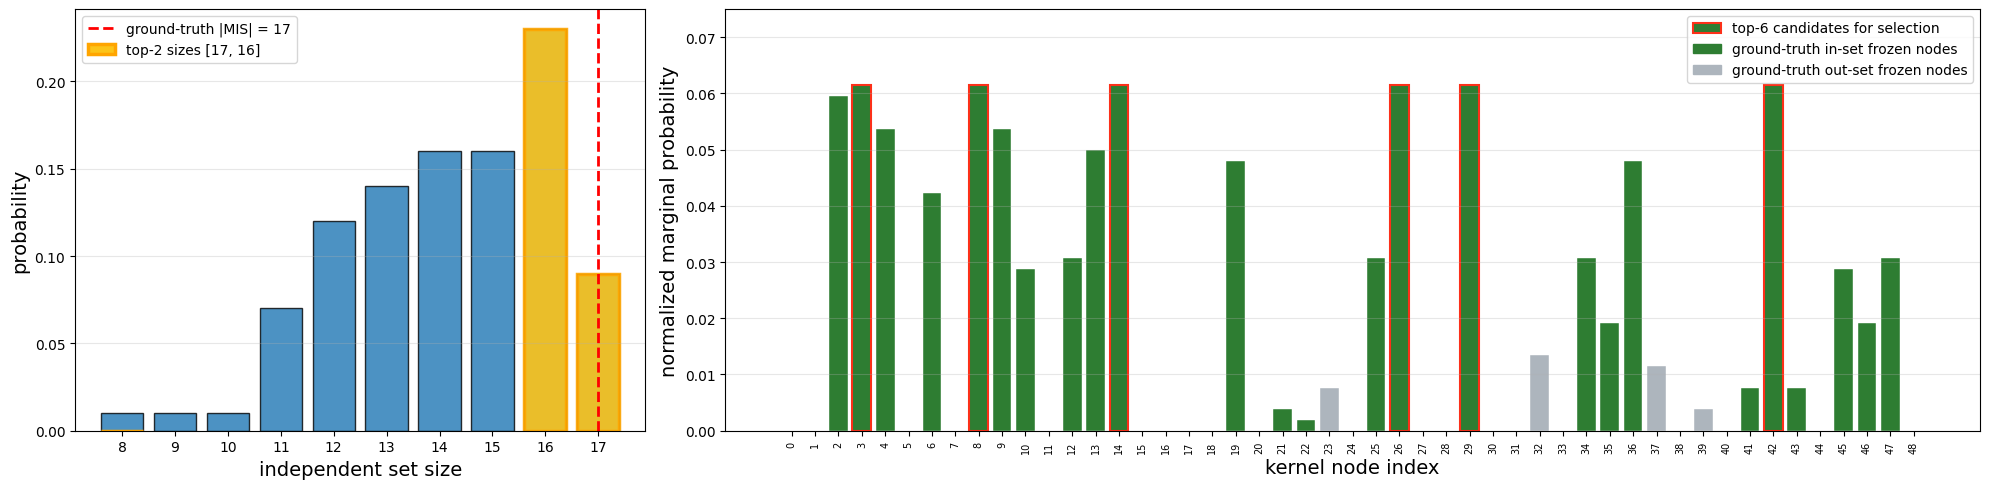

In [10]:
# Figure 4: fixed-IS size distribution and top-2-size normalized node marginals.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 5),
                                gridspec_kw={"width_ratios": [1, 2.2]})

size_counts = Counter()
for entry in fixup_counts:
    size_counts[len(entry['nodes'])] += entry['count']
sizes = sorted(size_counts)
total_shots = sum(size_counts.values())
probs_is = [size_counts[s] / total_shots for s in sizes]

ax1.bar(sizes, probs_is, edgecolor="k", alpha=0.8)
ax1.axvline(gt_size_kernel, color="red", ls="--", lw=2,
            label=f"ground-truth |MIS| = {gt_size_kernel}")
ax1.set_xlabel("independent set size", fontsize=14)
ax1.set_ylabel("probability", fontsize=14)
ax1.set_xticks(sizes)
ax1.grid(axis='y', alpha=0.3)
for s in top2_sizes:
    ax1.bar(s, probs_is[sizes.index(s)], edgecolor="orange", linewidth=2.5,
            color='#fcc419', alpha=0.9)
ax1.bar(sizes[0], 0, edgecolor="orange", linewidth=2.5,
        color='#fcc419', label=f"top-2 sizes {top2_sizes}")
ax1.legend(fontsize=10)

# Top six highest-probability candidate nodes receive red outlines.
top6_indices = sorted(range(len(norm_probs_top2)),
                      key=lambda i: norm_probs_top2[i], reverse=True)[:6]
top6_nodes = {all_nodes[i] for i in top6_indices}
x = np.arange(len(all_nodes))
bar_colors = ["#2E7D32" if n in gt_frozen_nodes or n in top6_nodes
              else '#adb5bd' for n in all_nodes]
edge_colors = ["#fc3019" if n in top6_nodes else "white" for n in all_nodes]
edge_widths = [1.5 if n in top6_nodes else 0.3 for n in all_nodes]
ax2.bar(x, norm_probs_top2, color=bar_colors,
        edgecolor=edge_colors, linewidth=edge_widths)
ax2.set_xticks(x)
ax2.set_xticklabels(range(len(all_nodes)), rotation=90, fontsize=7)
ax2.set_xlabel("kernel node index", fontsize=14)
ax2.set_ylabel("normalized marginal probability", fontsize=14)
ax2.grid(axis='y', alpha=0.3)
ax2.set_ylim([0, 0.075])
ax2.legend(handles=[
    Patch(facecolor="#2E7D32", edgecolor="#fc3019", linewidth=1.5,
          label="top-6 candidates for selection"),
    Patch(color="#2E7D32", label="ground-truth in-set frozen nodes"),
    Patch(color='#adb5bd', label="ground-truth out-set frozen nodes"),
], fontsize=10, loc='upper right')

plt.tight_layout()
if SAVE_FIGURES:
    os.makedirs("figures", exist_ok=True)
    plt.savefig("figures/comparison_qaoa_vs_qredumis_dax_rev_rev.png",
                dpi=300, bbox_inches="tight")
plt.show()

In [11]:
# Numbers quoted in the text around Fig. 4
in_set_mass = sum(p for n, p in zip(all_nodes, norm_probs_top2) if n in gt_frozen_nodes)
p_optimum = size_counts.get(gt_size_kernel, 0) / total_shots
print(f"Kernel MIS size: {gt_size_kernel}  ({len(all_mis)} optimal sets)")
print(f"Top-2 marginal mass on ground-truth in-set nodes: {in_set_mass:.1%}")
print(f"Probability of sampling an optimal IS: {p_optimum:.1%}")

Kernel MIS size: 17  (46 optimal sets)
Top-2 marginal mass on ground-truth in-set nodes: 96.4%
Probability of sampling an optimal IS: 9.0%
